![WEkEO by Copernicus and Partners](https://github.com/wekeo/frameworks/blob/main/img/WEkEO_banner_EUMETSAT.png?raw=true)

<div style="display: flex; justify-content: space-between;">
  <a href="./README.md">&lt;&lt; README</a>
  <a href="./02_Introduction_to_EOCanvas_API.ipynb">Introduction to the EOCanvas API &gt;&gt;</a>
</div>

Copyright (c) 2024 European Union 

License: MIT

# An introduction to the EOCanvas

**This notebook can be run on the WEkEO JupyterHub. You can also view it on GitHub.**

[![launch-WEKEO](https://img.shields.io/badge/launch-WEKEO-1a4696.svg)](https://jupyterhub.prod.wekeo2.eu/hub/user-redirect/lab/tree/public/wekeo4data/wekeo-eocanvas/01_Introduction_to_EOCanvas.ipynb)
[![github](https://img.shields.io/badge/Open%20in-GitHub-black?logo=github)](https://github.com/wekeo/wekeo-eocanvas/blob/main/01_Introduction_to_EOCanvas.ipynb)

**PREREQUISITES**

This notebook has the following prerequisites:
- [A WEkEO account](https://my.wekeo.eu/user-registration)

**LEARNING OUTCOMES**

At the end of this notebook you will know:

- what the EOCanvas service of WEkEO is
- how to build your own SNAP process in the EOCanvas
- how to subset a Sentinel-3 OLCI satellite image using the EOCanvas

**CONTENTS**

1. [Introduction to the EOCanvas](#1-introduction-to-the-eocanvas)  
2. [Setting up](#2-setting-up)  
3. [Inputs to the EOCanvas process](#3-inputs-to-the-eocanvas-process)  
4. [Execution of the process](#4-execution-of-the-process)  
5. [Examine the result](#5-examine-the-result)  
6. [Take home messages](#6-take-home-messages)  
7. [Next steps](#7-next-steps)

<hr>

The The EOCanvas is a WEkEO service to process Coperncius data in the Cloud. This notebooks gives an introduction of the service and how a process is built up and executed. You will use the software package SNAP to make a spatial subset of a Senitnel-3 tile within the cloud and only download the result of the process.

## 1. Introduction to the EOCanvas

**In short:  What is the WEkEO EOCanvas?**

WEkEO EOCanvas is a service to bring serverless processing for all Copernicus data to users. The EOCanvas python module or API enables users to process and analyse data without downloading any files to the local directory. In general, all data, which is available though the <a href='https://www.wekeo.eu/docs/harmonised-data-access-api' target='_blank'>Harmonised Data Access (HDA) API</a> can be processed throu the EOCanvas service. The processes are executed on the cloud, so that only the final result is downloaded to the local directory. 

**In short: Which processes are available?**

The EOCanvas is made for the work with Earth Observation data. Therefore, EOCanvas relies on specialized Earth Observation data analysis software which is already used in the user community to bring the processes to users. 

Currently, there are two software packages inplemented in the EOCanvas: 

- <a href='https://step.esa.int/main/toolboxes/snap/' target='_blank'>SeNtinel Application Platform SNAP</a> 
- <a href='https://user.eumetsat.int/resources/user-guides/data-tailor-standalone-guide' target='_blank'>EUMETSAT Data Tailor</a>

Any process you can perform within the software can also be applied within the EOCanvas. Existing workflows from projects using the software can be easily converted to a serverless workflow by simply proviting the SNAP graph or configutation file to the EOCanvas API. 

## 2. Setting up

Install eocanvas to your environment.

In [ ]:
! pip install -q eocanvas

Load necessary modules:

In [1]:
import os
import glob

from eocanvas import API, Credentials
from eocanvas.api import Input, Config, ConfigOption
from eocanvas.processes import SnapProcess
from eocanvas.snap.graph import Graph

from hda import Client
import xarray as xr
import getpass
import hda
from pathlib import Path

### Setup the WEkEO HDA and credentials

To use the WEkEO HDA adaptor, create a file called `.hdarc` in your home directory:

Add the following lines to the file:

`user:<your_user_name>`

`password:<your_password>`

For more information about the HDA and how to set up your credentials, check out [this notebook](https://github.com/wekeo/wekeo-hda/blob/master/wekeo_harmonised_data_access_api.ipynb).

The EOCanvas reads your WEkEO credentials from the same `.hdarc` file.

Lets create our credentials file, if it doesn't already exist.

In [ ]:
 # load credentials
wekeo_credentials_file = Path(Path.home() / '.hdarc' )

def get_credentials():
    user = input('Enter your WEkEO user name: ').strip()
    password = getpass.getpass('Enter your WEkEO password: ').strip()
    return user, password

def save_credentials(user, password):
    os.makedirs(os.path.dirname(wekeo_credentials_file), exist_ok=True)
    with open(wekeo_credentials_file, "w", encoding="utf-8") as f:
        f.write(f'user: {user}\npassword: {password}')

# Try loading saved credentials
if not wekeo_credentials_file.is_file():
    user, password = get_credentials()
    save_credentials(user, password)

# Try to get token, retry if credentials are invalid
while True:
    try:
        token = hda.Client().token
        print(f"Your WEkEO token: '{token}'")
        break  # Exit loop if successful
    except hda.api.ConfigurationError as e:
        print("Invalid username or password. Please try again.")
        print (e)
        user, password = get_credentials()
        save_credentials(user, password)

## 3. Inputs to the EOCanvas process

To process data using the EOCAnvas Serverless Functions, there are **three necessary inputs** to provide to the function:

 1. Data
 2. Processing Workflow
 3. Configuration Parameters

 Let's take a look at each of the inputs using the simple example:
 
 We want to use the serverless function to creating a subset of a Senitnel-3 WFR tile ("1") over a small area of interest over the Baltic Sea ("2"). 

<img src='./img/01_Introduction_Subset_S3.png' alt='' align='centre' width='30%'></img>

### 3.1 Data

The data is given to the serverless function as an **url**. The url is the reference location of the data in the WEkEO HDA. 

To get the url, you need to make a **request for the data using the WEkEO HDA**.

In [2]:
c= Client()

q = {
    "dataset_id": "EO:EUM:DAT:SENTINEL-3:OL_2_WFR___",
    "dtstart": "2024-08-06T08:58:00.000Z",
    "dtend": "2024-08-06T09:00:00.000Z",
    "timeliness": "NT"
}

r = c.search(q)
url = r.get_download_urls()[0]
inputs = Input(key="img1", url=url)

The `url` is the first input to the serverless function. 

### 3.2 Processing workflow

The serverless functions take **workflows coming from common Earth observation data software as input, e.g. the software SNAP**. 

You can build processing workflows using the **SNAP desktop software**. The graphs will look like this in the Graphical User Interface. You can also view the **xml graph** of the processing workflow. The xml graph is then the input to the serverless functions. 

<img src='./img/01_Introduction_SNAP_Graph_Subset.png' alt='' align='centre' width='40%'></img>
<img src='./img/01_Introduction_SNAP_xmlGraph_Subset.png' alt='' align='centre' width='20%'></img>

You can find the xml Graph for subsetting the area of interest in the file `subset_olci.xml`. Let's now import the file as Graph input. 

In [3]:
graph = Graph.from_uri("input_graphs/subset_olci.xml")

### 3.3 Configuration parameters

Depending on how the data input looks like, there are several preprocessing steps necessary, e.g. unzipping. This is defined in the `Config` input to the serverless functions. 

In [4]:
config = Config(key="img1", options=ConfigOption(uncompress=True, sub_path="xfdumanifest.xml"))

## 4. Execution of the process

Now everything is in place to launch the serverless function and run the process. 

In [5]:
process = SnapProcess(snap_graph=graph, eo_config=config, eo_input=inputs)

In [6]:
process.prepare_inputs()

{'inputs': {'snap_graph': 'PGdyYXBoIGlkPSJHcmFwaCI+CiAgPHZlcnNpb24+MS4wPC92ZXJzaW9uPgogIDxub2RlIGlkPSJSZWFkIj4KICAgIDxvcGVyYXRvcj5SZWFkPC9vcGVyYXRvcj4KICAgIDxzb3VyY2VzLz4KICAgIDxwYXJhbWV0ZXJzIGNsYXNzPSJjb20uYmMuY2VyZXMuYmluZGluZy5kb20uWHBwRG9tRWxlbWVudCI+CiAgICAgIDx1c2VBZHZhbmNlZE9wdGlvbnM+ZmFsc2U8L3VzZUFkdmFuY2VkT3B0aW9ucz4KICAgICAgPGZpbGU+JGltZzE8L2ZpbGU+CiAgICAgIDxjb3B5TWV0YWRhdGE+dHJ1ZTwvY29weU1ldGFkYXRhPgogICAgICA8YmFuZE5hbWVzLz4KICAgICAgPHBpeGVsUmVnaW9uPjAsMCw0ODY1LDQwOTE8L3BpeGVsUmVnaW9uPgogICAgICA8bWFza05hbWVzLz4KICAgIDwvcGFyYW1ldGVycz4KICA8L25vZGU+CiAgPG5vZGUgaWQ9IlN1YnNldCI+CiAgICA8b3BlcmF0b3I+U3Vic2V0PC9vcGVyYXRvcj4KICAgIDxzb3VyY2VzPgogICAgICA8c291cmNlUHJvZHVjdCByZWZpZD0iUmVhZCIvPgogICAgPC9zb3VyY2VzPgogICAgPHBhcmFtZXRlcnMgY2xhc3M9ImNvbS5iYy5jZXJlcy5iaW5kaW5nLmRvbS5YcHBEb21FbGVtZW50Ij4KICAgICAgPHNvdXJjZUJhbmRzPkNITF9OTixDSExfTk5fdW5jLENITF9PQzRNRSxDSExfT0M0TUVfdW5jLGxhdGl0dWRlLGxvbmdpdHVkZTwvc291cmNlQmFuZHM+CiAgICAgIDx0aWVQb2ludEdyaWRzLz4KICAgICAgPHJlZ2lvbj4wLDAsMCwwPC9yZWdpb

Calling Process.run, the process will be submitted. You can set the directory in which the results should be downloaded using `download_dir`. 

It will block until the results have been downloaded. Depending on the process, this can take a while. 

In [7]:
process.run(download_dir="result")

Job: eb84e267-08c6-516a-974e-d90cb5b621ee - Status: accepted at 2025-09-30T08:54:10.871528
Job: eb84e267-08c6-516a-974e-d90cb5b621ee - Status: running at 2025-09-30T08:54:21.218123
Job: eb84e267-08c6-516a-974e-d90cb5b621ee - Status: running at 2025-09-30T08:54:32.488516
Job: eb84e267-08c6-516a-974e-d90cb5b621ee - Status: running at 2025-09-30T08:54:44.921610
Job: eb84e267-08c6-516a-974e-d90cb5b621ee - Status: running at 2025-09-30T08:54:58.543947
Job: eb84e267-08c6-516a-974e-d90cb5b621ee - Status: running at 2025-09-30T08:55:13.487547
Job: eb84e267-08c6-516a-974e-d90cb5b621ee - Status: running at 2025-09-30T08:55:29.868820
Job: eb84e267-08c6-516a-974e-d90cb5b621ee - Status: running at 2025-09-30T08:55:47.883593
Job: eb84e267-08c6-516a-974e-d90cb5b621ee - Status: running at 2025-09-30T08:56:07.689572


## 5. Examine the result

The result is stored in the directory and can be examined using common python tools, such as xarray. 

In [2]:
result =  glob.glob("result/*.nc")[0]
result

'result\\6c2a2db4-9dca-11f0-9901-0a5e9884a670.nc'

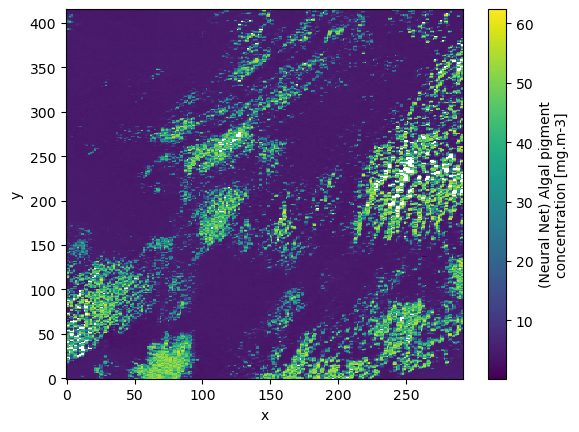

In [4]:
xr.open_dataset(result).CHL_NN.plot()

## 6. Take home messages

- The EOCanvas runs processing workflows on WEkEO in the cloud, so you only download the results.
- An EOCanvas SNAP process needs three inputs: the data (a download URL from the WEkEO HDA), the processing workflow (a SNAP graph) and the configuration parameters.
- `process.run()` submits the process, waits until it has finished and downloads the result.

## 7. Next steps

You have just successfully subsetted a Sentinel-3 scene using the WEkEO EOCancas serverless functions. The next tutorial will give you a better understanding of the API, introducing more practical features, such as receiving log files, monitoring your process status and manually triggering the download of the result after successful job execution.

<hr>

[View on GitHub](https://github.com/wekeo) | 
[Visit WEkEO](https://wekeo.copernicus.eu) | [Run Notebooks on the WEkEO Workspace](https://jupyterhub.prod.wekeo2.eu/) | 
[Contact helpdesk for support](mailto:support@wekeo.eu)